# 04 — The manuscript figures

**Python port of `fig03.m`, `fig04.m`, `fig05.m`, `fig06.m`, `fig07.m` and `figA2.m`.**

These six scripts generate the figures that appear in the paper and print the
accompanying statistical tests to the console. This notebook reproduces both.

| Figure | Question |
|---|---|
| **3** | Do $\alpha$ and $\beta$ differ between the two test positions, within each mode? |
| **4** | Do the Type A and Type B effects in the two modes go together? |
| **5** | Is the DL from aggregated data larger in sequential than in simultaneous mode? |
| **6** | Within a mode, how do DLs from test-first, test-second and aggregated fits relate? |
| **7** | Does the sequential-vs-simultaneous DL difference survive disaggregation? |
| **A2** | Are the two candidate definitions of DL interchangeable? |



In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('.'))
import orderfx as O

PROJECT_ROOT = os.path.abspath('..')
REFERENCE_DIR = os.path.join(os.path.abspath('.'), 'reference')
OUTPUT_DIR = os.path.join(os.path.abspath('.'), 'outputs')
FIG_DIR = os.path.join(OUTPUT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

# Set to the FORTRAN table to reproduce the published numbers exactly; the
# Python fits differ only in the handful of cells where alpha_1 is not
# identifiable (see the verification section at the end).
USE_FORTRAN_FITS = False

fit_path = os.path.join(REFERENCE_DIR, 'fit_all.csv') if USE_FORTRAN_FITS \
    else os.path.join(OUTPUT_DIR, 'fit_all_python.csv')

def load_fits(path):
    r = pd.read_csv(path, skipinitialspace=True)
    r.columns = [c.strip() for c in r.columns]
    for c in ['Obs_code', 'Task', 'Test_order_location']:
        r[c] = r[c].astype(str).str.strip()
    return r

results = load_fits(fit_path)
print('using', os.path.basename(fit_path), '-', len(results), 'fits')

def split_task(r, task):
    '''Return [position 1, position 2, aggregated] tables for one task,
    each sorted identically so rows line up across the three.'''
    s = r[r.Task == O.TASK_LABELS[task]]
    return [s[s.Test_order_location == lab]
            .sort_values(['Obs_number', 'Condition']).reset_index(drop=True)
            for lab in O.ORDER_LABELS[task]]

P = {t: split_task(results, t) for t in (0, 1)}

# Colour points by standard luminance, as the figure scripts do.
STD_COLOUR = {13.2: 'red', 26.4: 'green', 39.5: 'blue'}
def colours(standards):
    return [STD_COLOUR.get(round(s, 1), 'gray') for s in standards]

def corner_text(ax, count, n, rng, corner):
    txt = f'{count} ({100 * count / n:.2f}%)'
    x, y, ha, va = {'tl': (rng[0], rng[1], 'left', 'top'),
                    'bl': (rng[0], rng[0], 'left', 'bottom'),
                    'tr': (rng[1], rng[1], 'right', 'top'),
                    'br': (rng[1], rng[0], 'right', 'bottom')}[corner]
    ax.text(x, y, '  ' + txt + '  ', ha=ha, va=va, fontweight='bold', fontsize=9)

def show_score(label, count, n):
    s = O.score_test(count, n)
    print(f'{label}')
    print(f"   z = {s['z']:.4f}, p = {s['p_value']:.4g}, "
          f"95% CI: [{s['CI'][0]:.4f}, {s['CI'][1]:.4f}]")

def show_t(label, x):
    r = O.one_sample_t(np.asarray(x, dtype=float))
    print(f'{label}')
    print(f"   mean: {r['mean']:.4f}, SD: {r['sd']:.4f}, t = {r['t']:.4f}, "
          f"df = {r['df']}, p = {r['p_value']:.4g}, "
          f"95% CI: [{r['CI'][0]:.4f}, {r['CI'][1]:.4f}]")

def show_corr(label, x, y):
    r = O.correlation_test(np.asarray(x, dtype=float), np.asarray(y, dtype=float))
    print(f'{label}')
    print(f"   r = {r['r']:.4f}, t = {r['t']:.4f}, df = {r['df']}, "
          f"p = {r['p_value']:.4g}, 95% CI: [{r['CI'][0]:.4f}, {r['CI'][1]:.4f}]")

using fit_all_python.csv - 504 fits


## Figure 3 — location and slope at each test position

One panel pair per mode: $\alpha$ on the left, $\beta$ on the right, with the
value for test-second (or test-right) plotted against the value for test-first
(or test-left). Points are coloured by standard luminance — red 13.2, green
26.4, blue 39.5 cd/m².

Note that $\alpha$ is plotted in **native units** ($e^{\alpha}$, cd/m²) rather
than log units, and that the exclusion uses only the two disaggregated fits
(`df > 0` for positions 1 and 2), not the aggregated one. That is why the
sequential panel keeps all 84 cases.

The bold corner numbers count points above the diagonal (top-left) and below it
(bottom-right), and the Score tests below ask whether those counts depart from
50%.

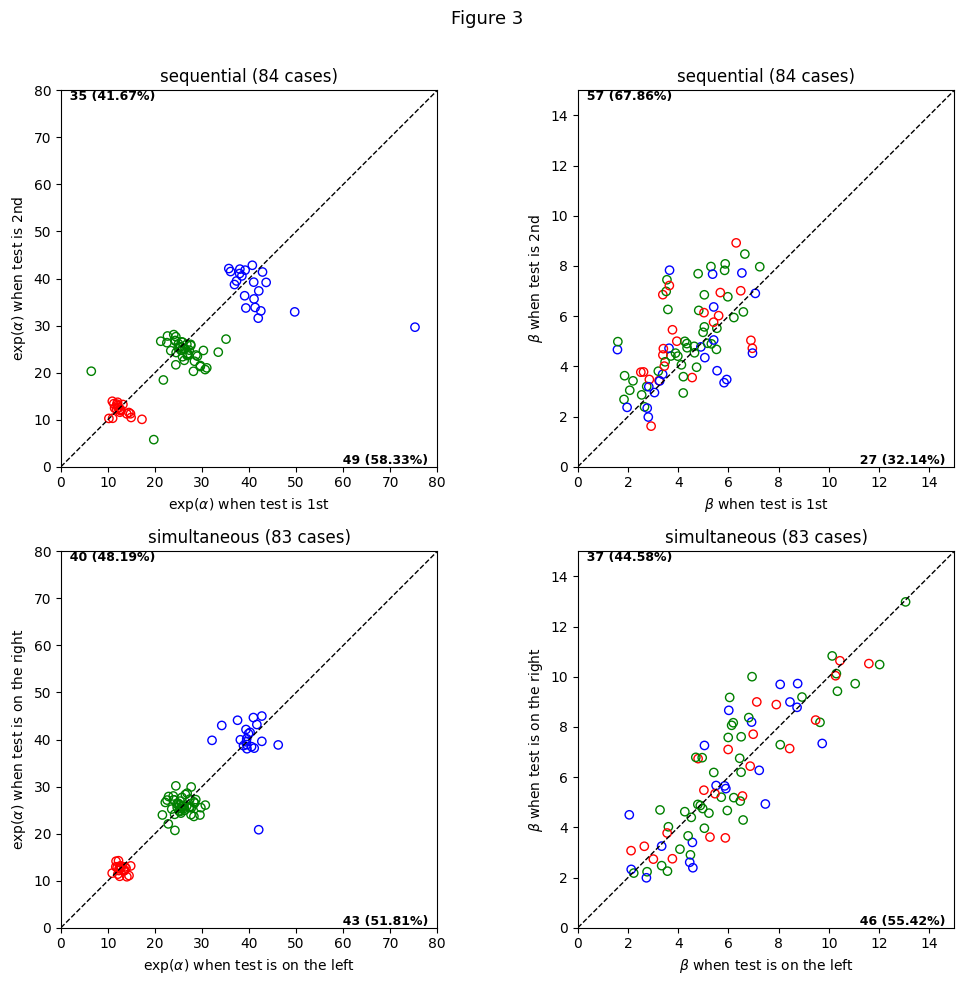

Score test for prop(alpha_TF < alpha_TS) = 0.5 in sequential mode:  35 of 84 (41.67%)
   z = -1.5275, p = 0.1266, 95% CI: [0.3171, 0.5235]
Score test for prop(alpha_TF < alpha_TS) = 0.5 in simultaneous mode:  40 of 83 (48.19%)
   z = -0.3293, p = 0.7419, 95% CI: [0.3776, 0.5878]
Score test for prop(beta_TF < beta_TS) = 0.5 in sequential mode:  57 of 84 (67.86%)
   z = 3.2733, p = 0.001063, 95% CI: [0.5728, 0.7687]
Score test for prop(beta_TF < beta_TS) = 0.5 in simultaneous mode:  37 of 83 (44.58%)
   z = -0.9879, p = 0.3232, 95% CI: [0.3436, 0.5527]


In [2]:
fig3, axes = plt.subplots(2, 2, figsize=(10.5, 10))
fig3_stats = {}

for task in (0, 1):
    r1, r2, _ = P[task]
    keep = (r1['df'] > 0) & (r2['df'] > 0)
    a1, a2 = r1[keep], r2[keep]
    n = len(a1)
    lab = O.ORDER_LABELS[task]
    extra = 'on the ' if task == 1 else ''
    col = colours(a1.Standard)

    alpha_1 = (a1.Alpha_1 + a1.Alpha_2).to_numpy() / 2
    alpha_2 = (a2.Alpha_1 + a2.Alpha_2).to_numpy() / 2
    beta_1, beta_2 = a1.Beta.to_numpy(), a2.Beta.to_numpy()

    # ---- alpha, in native units
    ax = axes[task, 0]
    rng = (0, 80)
    ax.scatter(np.exp(alpha_1), np.exp(alpha_2), facecolors='none', edgecolors=col)
    ax.plot(rng, rng, 'k--', lw=1)
    ax.set_xlim(rng); ax.set_ylim(rng); ax.set_aspect('equal')
    ax.set_xlabel(rf'exp($\alpha$) when test is {extra}{lab[0]}')
    ax.set_ylabel(rf'exp($\alpha$) when test is {extra}{lab[1]}')
    ax.set_title(f'{O.TASK_LABELS[task]} ({n} cases)')
    below = int((alpha_1 < alpha_2).sum())
    corner_text(ax, below, n, rng, 'tl')
    corner_text(ax, int((alpha_1 > alpha_2).sum()), n, rng, 'br')
    fig3_stats[('alpha', task)] = (below, n)

    # ---- beta
    ax = axes[task, 1]
    rng = (0, 15)
    ax.scatter(beta_1, beta_2, facecolors='none', edgecolors=col)
    ax.plot(rng, rng, 'k--', lw=1)
    ax.set_xlim(rng); ax.set_ylim(rng); ax.set_aspect('equal')
    ax.set_xlabel(rf'$\beta$ when test is {extra}{lab[0]}')
    ax.set_ylabel(rf'$\beta$ when test is {extra}{lab[1]}')
    ax.set_title(f'{O.TASK_LABELS[task]} ({n} cases)')
    below = int((beta_1 < beta_2).sum())
    corner_text(ax, below, n, rng, 'tl')
    corner_text(ax, int((beta_1 > beta_2).sum()), n, rng, 'br')
    fig3_stats[('beta', task)] = (below, n)

fig3.suptitle('Figure 3', fontsize=13)
fig3.tight_layout(rect=[0, 0, 1, 0.97])
fig3.savefig(os.path.join(FIG_DIR, 'fig03.png'), dpi=150)
fig3.savefig(os.path.join(FIG_DIR, 'fig03.pdf'))
plt.show()

for task in (0, 1):
    c, n = fig3_stats[('alpha', task)]
    show_score(f'Score test for prop(alpha_TF < alpha_TS) = 0.5 in '
               f'{O.TASK_LABELS[task]} mode:  {c} of {n} ({100*c/n:.2f}%)', c, n)
for task in (0, 1):
    c, n = fig3_stats[('beta', task)]
    show_score(f'Score test for prop(beta_TF < beta_TS) = 0.5 in '
               f'{O.TASK_LABELS[task]} mode:  {c} of {n} ({100*c/n:.2f}%)', c, n)

## Figure 4 — Type A and Type B effects across modes

Now the two modes are compared directly: the effect in the simultaneous mode on
the x axis against the same effect in the sequential mode on the y axis. Here
the exclusion requires `df > 0` in **all four** disaggregated fits, so both
panels use the same 83 cases.

The four bold numbers count the points in each quadrant. Alongside the figure,
`fig04.m` prints Score tests for the prevalence of negative effects, one-sample
t tests on the magnitudes, and a test of the correlation between modes.

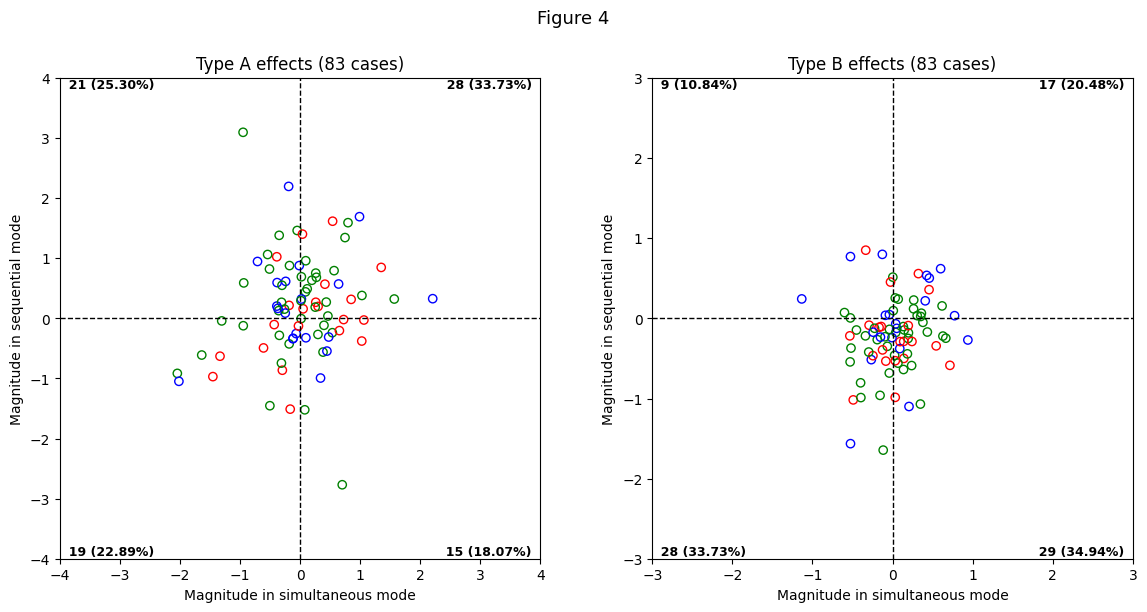

Score test for prop(Type_A_simultaneous < 0) = 0.5:
   z = -0.3293, p = 0.7419, 95% CI: [0.3776, 0.5878]
Score test for prop(Type_A_sequential < 0) = 0.5:
   z = -1.6465, p = 0.09967, 95% CI: [0.3101, 0.5171]
One-sample t-test for mean(Type_A_simultaneous) = 0:
   mean: 0.0006, SD: 0.7177, t = 0.0082, df = 82, p = 0.9935, 95% CI: [-0.1570, 0.1583]
One-sample t-test for mean(Type_A_sequential) = 0:
   mean: 0.1927, SD: 0.8681, t = 2.0102, df = 82, p = 0.0477, 95% CI: [0.0020, 0.3834]
t-test for corr(Type_A_sequential, Type_A_simultaneous) = 0:
   r = 0.1550, t = 1.4125, df = 81, p = 0.1616, 95% CI: [-0.0627, 0.3587]

Score test for prop(Type_B_simultaneous < 0) = 0.5:
   z = -0.9879, p = 0.3232, 95% CI: [0.3436, 0.5527]
Score test for prop(Type_B_sequential < 0) = 0.5:
   z = 3.4027, p = 0.0006673, 95% CI: [0.5806, 0.7764]
One-sample t-test for mean(Type_B_simultaneous) = 0:
   mean: 0.0292, SD: 0.3635, t = 0.7282, df = 82, p = 0.4686, 95% CI: [-0.0506, 0.1091]
One-sample t-test for mea

In [3]:
keep4 = ((P[0][0]['df'] > 0) & (P[0][1]['df'] > 0)
         & (P[1][0]['df'] > 0) & (P[1][1]['df'] > 0))
s1, s2 = P[0][0][keep4], P[0][1][keep4]
m1, m2 = P[1][0][keep4], P[1][1][keep4]
standards = s1.Standard.to_numpy()

A_seq = O.type_a_effect(s1.Alpha_1, s1.Alpha_2, s1.Beta, s2.Alpha_1, s2.Alpha_2, s2.Beta)
A_sim = O.type_a_effect(m1.Alpha_1, m1.Alpha_2, m1.Beta, m2.Alpha_1, m2.Alpha_2, m2.Beta)
B_seq = O.type_b_effect(s1.Beta, s2.Beta)
B_sim = O.type_b_effect(m1.Beta, m2.Beta)
n4 = len(A_seq)

fig4, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, xs, ys, rng, name in [(axes[0], A_sim, A_seq, (-4, 4), 'Type A'),
                              (axes[1], B_sim, B_seq, (-3, 3), 'Type B')]:
    ax.scatter(xs, ys, facecolors='none', edgecolors=colours(standards))
    ax.axvline(0, color='k', ls='--', lw=1)
    ax.axhline(0, color='k', ls='--', lw=1)
    ax.set_xlim(rng); ax.set_ylim(rng); ax.set_aspect('equal')
    corner_text(ax, int(((xs < 0) & (ys > 0)).sum()), n4, rng, 'tl')
    corner_text(ax, int(((xs > 0) & (ys > 0)).sum()), n4, rng, 'tr')
    corner_text(ax, int(((xs < 0) & (ys < 0)).sum()), n4, rng, 'bl')
    corner_text(ax, int(((xs > 0) & (ys < 0)).sum()), n4, rng, 'br')
    ax.set_xlabel('Magnitude in simultaneous mode')
    ax.set_ylabel('Magnitude in sequential mode')
    ax.set_title(f'{name} effects ({n4} cases)')
fig4.suptitle('Figure 4', fontsize=13)
fig4.tight_layout(rect=[0, 0, 1, 0.95])
fig4.savefig(os.path.join(FIG_DIR, 'fig04.png'), dpi=150)
fig4.savefig(os.path.join(FIG_DIR, 'fig04.pdf'))
plt.show()

for name, sim, seq in [('Type_A', A_sim, A_seq), ('Type_B', B_sim, B_seq)]:
    show_score(f'Score test for prop({name}_simultaneous < 0) = 0.5:',
               int((sim < 0).sum()), n4)
    show_score(f'Score test for prop({name}_sequential < 0) = 0.5:',
               int((seq < 0).sum()), n4)
    show_t(f'One-sample t-test for mean({name}_simultaneous) = 0:', sim)
    show_t(f'One-sample t-test for mean({name}_sequential) = 0:', seq)
    show_corr(f't-test for corr({name}_sequential, {name}_simultaneous) = 0:', seq, sim)
    print()

Save the per-case effects alongside the figures, so the values behind Figure 4 are available as a table.

In [4]:
effects = pd.DataFrame({
    'Obs_number': s1.Obs_number.to_numpy(),
    'Obs_code': s1.Obs_code.to_numpy(),
    'Condition': s1.Condition.to_numpy(),
    'Standard': s1.Standard.to_numpy(),
    'TypeA_sequential': A_seq,
    'TypeA_simultaneous': A_sim,
    'TypeB_sequential': B_seq,
    'TypeB_simultaneous': B_sim,
})
effects.to_csv(os.path.join(OUTPUT_DIR, 'order_effects.csv'), index=False)
print(f'wrote order_effects.csv ({len(effects)} cases)')
effects.head()

wrote order_effects.csv (83 cases)


,Obs_number,Obs_code,Condition,Standard,TypeA_sequential,TypeA_simultaneous,TypeB_sequential,TypeB_simultaneous
0,1,Cap,0,26.4,0.322336,1.567170,-0.180239,0.197608
1,1,Cap,1,13.2,-0.027016,1.061758,-0.499617,0.139982
2,1,Cap,2,26.4,-0.238053,0.536579,-0.461016,0.025017
3,1,Cap,3,39.5,0.572424,0.640747,0.038326,-0.089862
4,2,Duck,0,26.4,0.590661,-0.937984,-0.175435,0.039528


## The difference limen

Figures 5 to 7 all rest on the DL derived in Appendix A. For the
same–different format the fitted function is non-monotonic, so the textbook
"distance between the 50% and 75% points" cannot be applied directly. Appendix A
shows that the corresponding monotonic function under the greater–less format
is $\Psi = [\Phi_1 + \Phi_2]/2$, whose

* 50% point is $x_{50} = (\alpha_1+\alpha_2)/2$ in closed form, and
* 75% point solves $\Phi_1(x) + \Phi_2(x) - 1.5 = 0$, which needs a numerical
  root finder.

`orderfx.difference_limen` does exactly this and returns the DL in native
units, $e^{x_{75}} - e^{x_{50}}$. MATLAB uses `fzero` seeded at $\alpha_2$; the
Python version brackets the root and uses Brent's method, which is more
robust and gives the same answer.

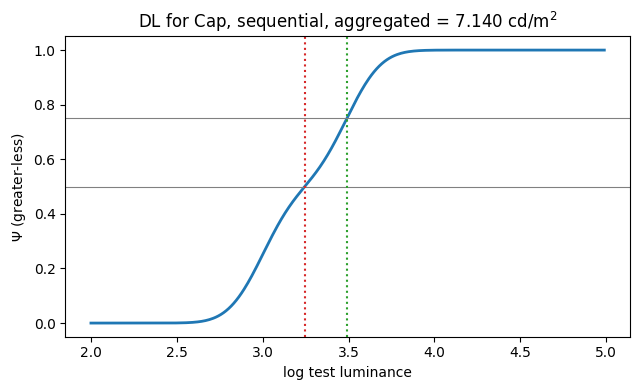

In [5]:
DL = {}
for task in (0, 1):
    DL[task] = [O.difference_limen(p.Alpha_1, p.Alpha_2, p.Beta) for p in P[task]]

# a quick illustration of where x75 sits
row = P[0][2].iloc[0]
xs = np.linspace(row.Alpha_1 - 1, row.Alpha_2 + 1.5, 400)
sd = 1 / row.Beta
from scipy.stats import norm
psi = (norm.cdf(xs, row.Alpha_1, sd) + norm.cdf(xs, row.Alpha_2, sd)) / 2
x50 = (row.Alpha_1 + row.Alpha_2) / 2
dl = O.difference_limen([row.Alpha_1], [row.Alpha_2], [row.Beta])
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(xs, psi, lw=2)
ax.axhline(0.5, color='gray', lw=0.8); ax.axhline(0.75, color='gray', lw=0.8)
ax.axvline(x50, color='tab:red', ls=':'); ax.axvline(np.log(np.exp(x50) + dl), color='tab:green', ls=':')
ax.set_xlabel('log test luminance'); ax.set_ylabel(r'$\Psi$ (greater-less)')
ax.set_title(f'DL for {row.Obs_code}, sequential, aggregated = {dl:.3f} cd/m$^2$')
fig.tight_layout(); plt.show()

## Figure 5 — DL from aggregated data, sequential vs simultaneous

This is the conventional comparison: one DL per observer and condition, from
the fit to data aggregated over presentation orders. Points above the diagonal
are cases where discrimination was *worse* (larger DL) in the sequential mode.

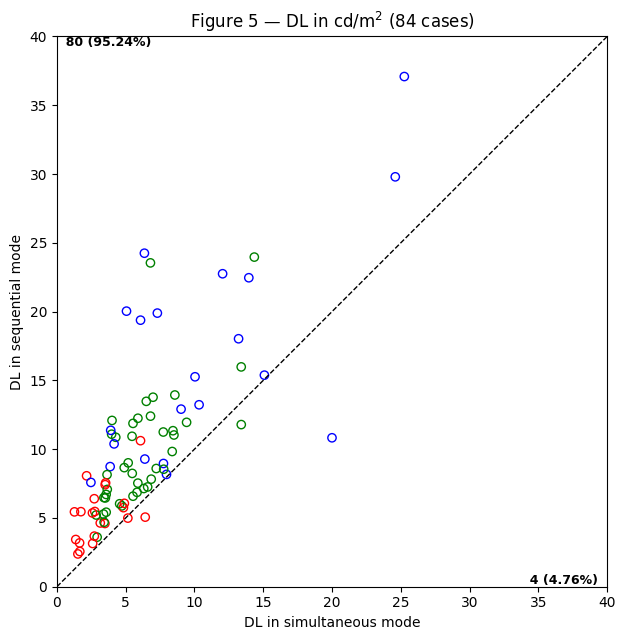

Score test for prop(DL_sim < DL_seq) = 0.5:
   z = 8.2923, p = 1.111e-16, 95% CI: [0.8839, 0.9813]

Paired-samples t-test for mean(DL_sim) = mean(DL_seq):
   simultaneous mean, SD: 6.4280  4.5545
     sequential mean, SD: 10.3270  6.3486
             correlation: 0.7680
   t = -8.7089, df = 83, p = 2.498e-13, 95% CI: [-4.7894, -3.0085]


In [6]:
keep5 = (P[0][2]['df'] > 0) & (P[1][2]['df'] > 0)
DL_seq_agg = DL[0][2][keep5.to_numpy()]
DL_sim_agg = DL[1][2][keep5.to_numpy()]
std5 = P[0][2][keep5].Standard.to_numpy()
n5 = len(DL_seq_agg)

fig5, ax = plt.subplots(figsize=(6.5, 6.5))
rng = (0, 40)
ax.scatter(DL_sim_agg, DL_seq_agg, facecolors='none', edgecolors=colours(std5))
ax.plot(rng, rng, 'k--', lw=1)
ax.set_xlim(rng); ax.set_ylim(rng); ax.set_aspect('equal')
corner_text(ax, int((DL_seq_agg > DL_sim_agg).sum()), n5, rng, 'tl')
corner_text(ax, int((DL_seq_agg < DL_sim_agg).sum()), n5, rng, 'br')
ax.set_xlabel('DL in simultaneous mode')
ax.set_ylabel('DL in sequential mode')
ax.set_title(f'Figure 5 — DL in cd/m$^2$ ({n5} cases)')
fig5.tight_layout()
fig5.savefig(os.path.join(FIG_DIR, 'fig05.png'), dpi=150)
fig5.savefig(os.path.join(FIG_DIR, 'fig05.pdf'))
plt.show()

show_score('Score test for prop(DL_sim < DL_seq) = 0.5:',
           int((DL_seq_agg > DL_sim_agg).sum()), n5)
pt = O.paired_t(DL_sim_agg, DL_seq_agg)
print('\nPaired-samples t-test for mean(DL_sim) = mean(DL_seq):')
print(f"   simultaneous mean, SD: {pt['mean_x']:.4f}  {pt['sd_x']:.4f}")
print(f"     sequential mean, SD: {pt['mean_y']:.4f}  {pt['sd_y']:.4f}")
print(f"             correlation: {pt['correlation']:.4f}")
print(f"   t = {pt['t']:.4f}, df = {pt['df']}, p = {pt['p_value']:.4g}, "
      f"95% CI: [{pt['CI'][0]:.4f}, {pt['CI'][1]:.4f}]")

## Figure 6 — DLs within a mode

Three pairwise comparisons per mode: test-first vs test-second, test-first vs
aggregated, and test-second vs aggregated. Each panel prints two correlations:

* $r$ — the ordinary product-moment correlation, which measures only how
  linearly related the two are;
* $r_c$ — **Lin's concordance correlation**, which additionally penalises
  departures from the identity line. Two measures can correlate perfectly and
  still disagree systematically; $r_c$ catches that, $r$ does not.

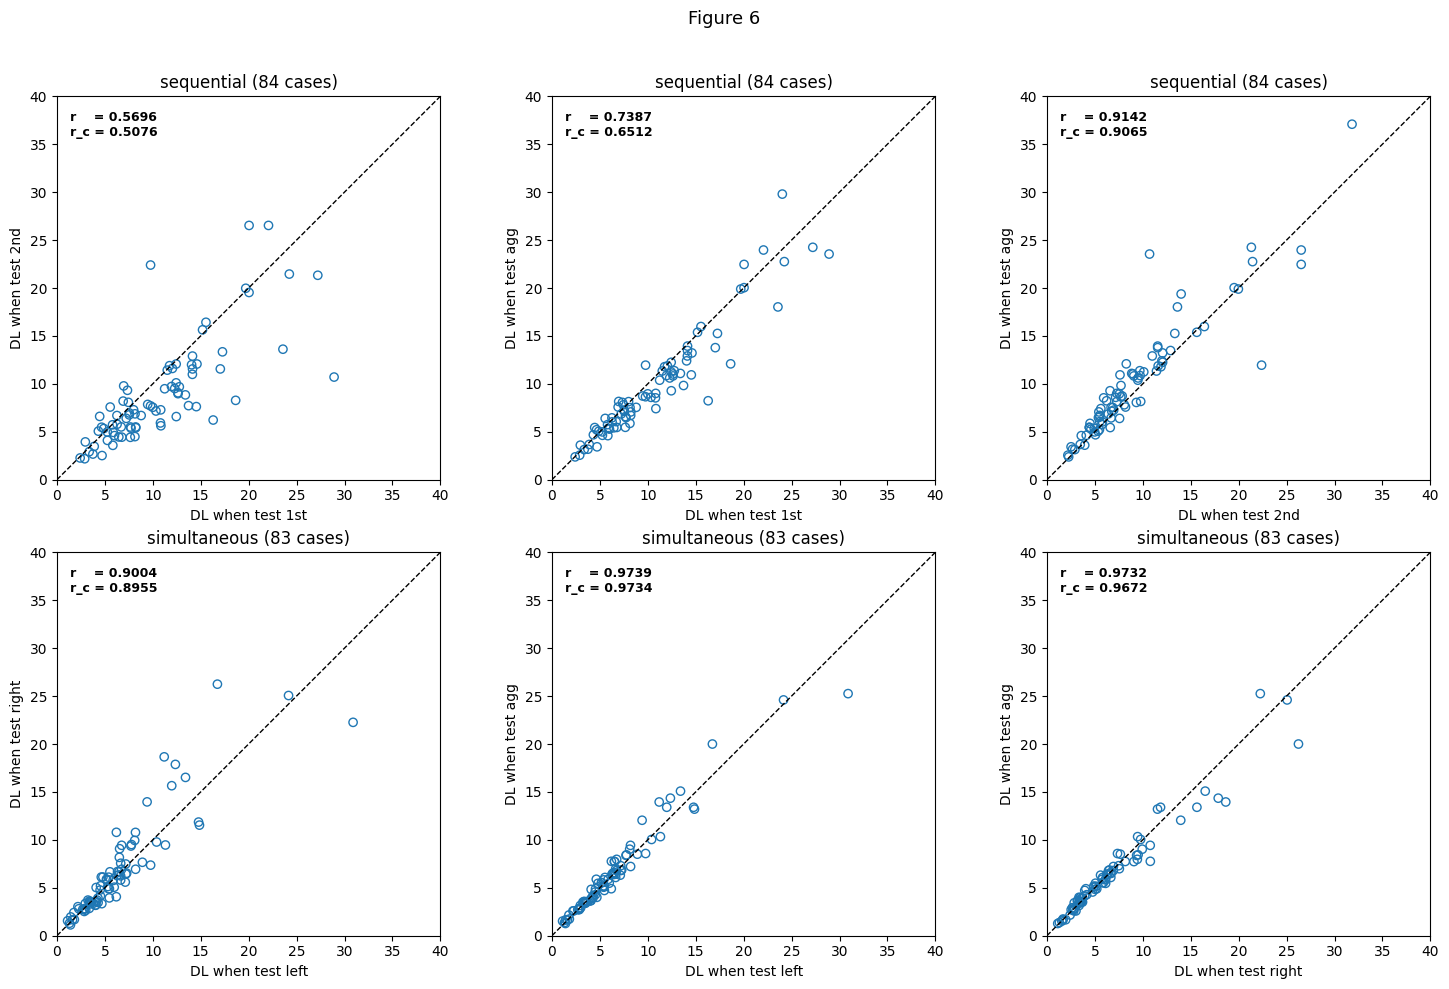

In [7]:
fig6, axes = plt.subplots(2, 3, figsize=(15, 10))
for task in (0, 1):
    keep = ((P[task][0]['df'] > 0) & (P[task][1]['df'] > 0)
            & (P[task][2]['df'] > 0)).to_numpy()
    d = [DL[task][k][keep] for k in range(3)]
    lab = O.ORDER_LABELS[task]
    n = keep.sum()
    col = 0
    for i in range(3):
        for j in range(i + 1, 3):
            ax = axes[task, col]; col += 1
            x, y = d[i], d[j]
            ax.scatter(x, y, facecolors='none', edgecolors='tab:blue')
            rng = (0, 40)
            ax.plot(rng, rng, 'k--', lw=1)
            ax.set_xlim(rng); ax.set_ylim(rng); ax.set_aspect('equal')
            ax.set_xlabel(f'DL when test {lab[i]}')
            ax.set_ylabel(f'DL when test {lab[j]}')
            ax.set_title(f'{O.TASK_LABELS[task]} ({n} cases)')
            r = np.corrcoef(x, y)[0, 1]
            rc = O.concordance_correlation(x, y)
            ax.text(rng[0], rng[1], f'\n   r    = {r:6.4f}\n   r_c = {rc:6.4f}',
                    ha='left', va='top', fontweight='bold', fontsize=9)
fig6.suptitle('Figure 6', fontsize=13)
fig6.tight_layout(rect=[0, 0, 1, 0.96])
fig6.savefig(os.path.join(FIG_DIR, 'fig06.png'), dpi=150)
fig6.savefig(os.path.join(FIG_DIR, 'fig06.pdf'))
plt.show()

## Figure 7 — DLs across modes, every combination

A 3 × 3 grid crossing the three sequential DLs (rows, ordered aggregated /
test-second / test-first from the top) with the three simultaneous DLs
(columns). The point is to check whether the sequential-vs-simultaneous
difference of Figure 5 depends on which psychometric function supplies the DL —
if it survives in all nine panels, the difference is not an artifact of
aggregation.

83 cases

sequential DL_agg > simultaneous DL_left: 78 (93.98%)  z = 8.0128, p = 1.12e-15
sequential DL_agg > simultaneous DL_right: 76 (91.57%)  z = 7.5737, p = 3.63e-14
sequential DL_agg > simultaneous DL_agg: 79 (95.18%)  z = 8.2323, p = 1.84e-16
sequential DL_2nd > simultaneous DL_left: 73 (87.95%)  z = 6.9151, p = 4.67e-12
sequential DL_2nd > simultaneous DL_right: 74 (89.16%)  z = 7.1347, p = 9.7e-13
sequential DL_2nd > simultaneous DL_agg: 73 (87.95%)  z = 6.9151, p = 4.67e-12
sequential DL_1st > simultaneous DL_left: 77 (92.77%)  z = 7.7933, p = 6.53e-15
sequential DL_1st > simultaneous DL_right: 76 (91.57%)  z = 7.5737, p = 3.63e-14
sequential DL_1st > simultaneous DL_agg: 78 (93.98%)  z = 8.0128, p = 1.12e-15


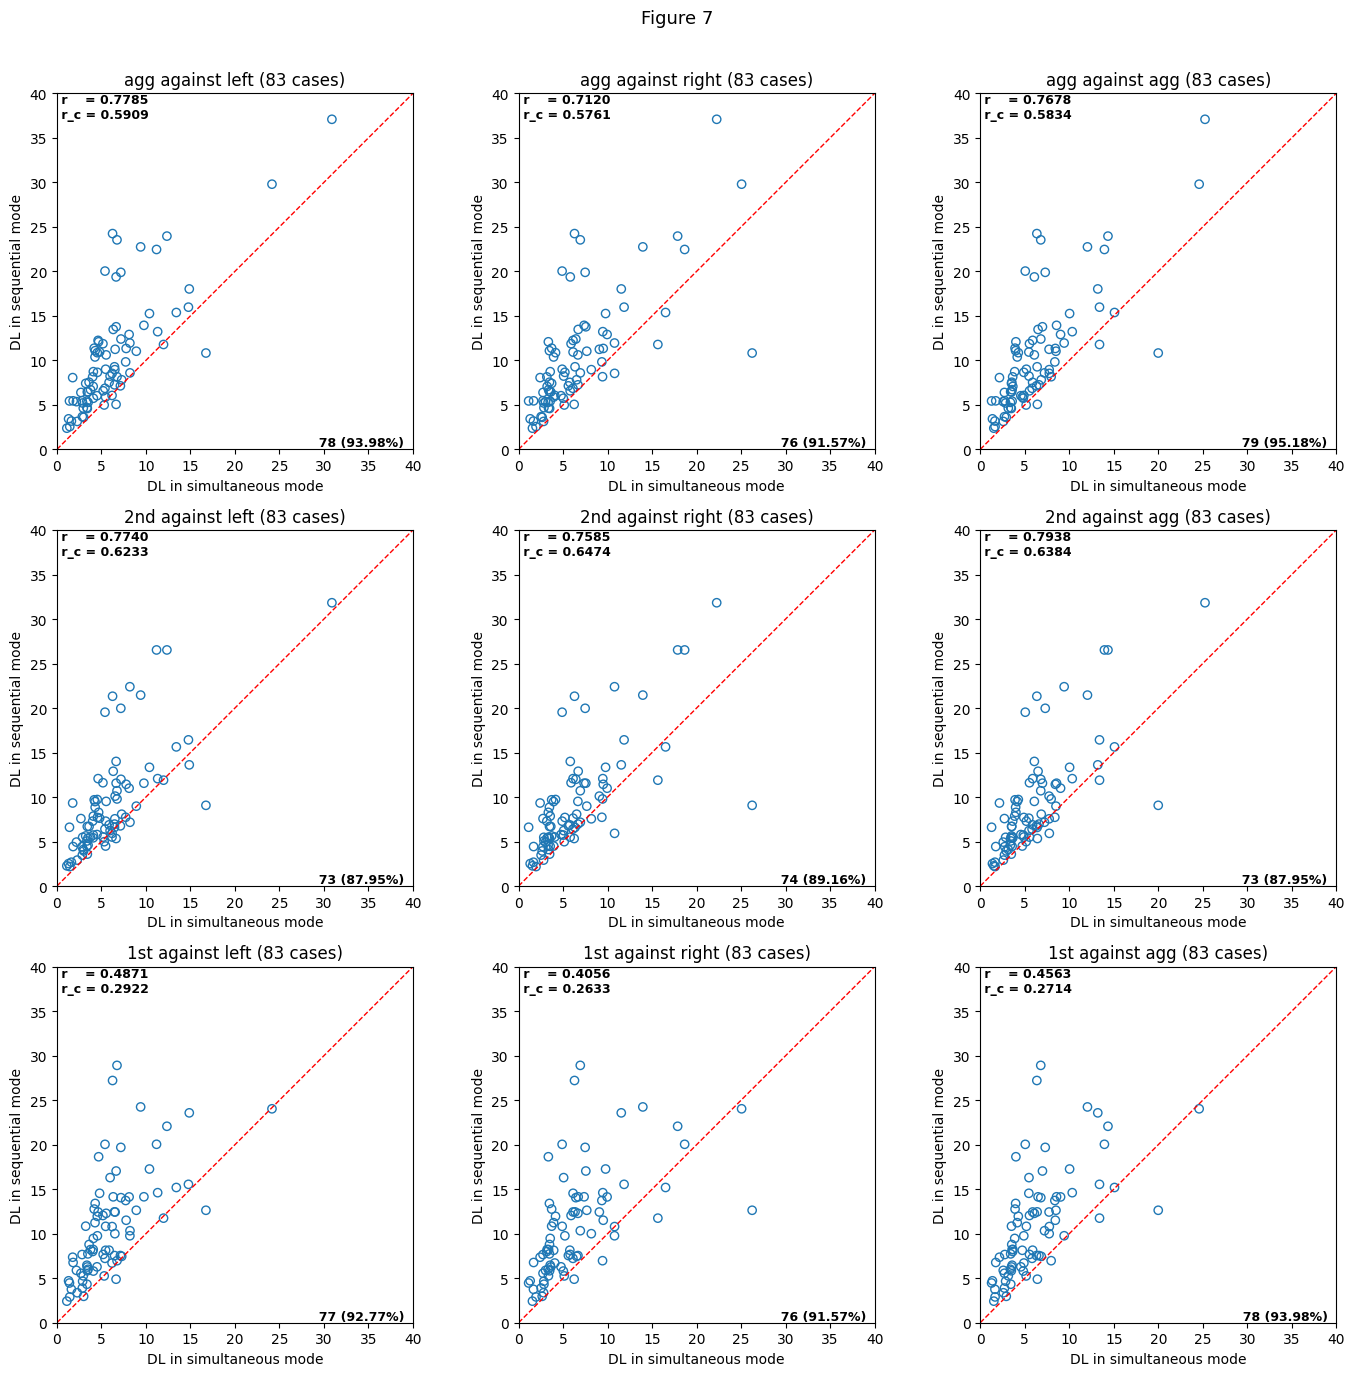

In [8]:
keep7 = np.ones(len(P[0][0]), dtype=bool)
for task in (0, 1):
    for k in range(3):
        keep7 &= (P[task][k]['df'] > 0).to_numpy()
dx = [DL[1][k][keep7] for k in range(3)]      # simultaneous, x axis
dy = [DL[0][k][keep7] for k in range(3)]      # sequential, y axis
n7 = int(keep7.sum())

fig7, axes = plt.subplots(3, 3, figsize=(14, 14))
print(f'{n7} cases\n')
for r_i, j in enumerate([2, 1, 0]):           # agg, 2nd, 1st down the rows
    for i in range(3):
        ax = axes[r_i, i]
        x, y = dx[i], dy[j]
        ax.scatter(x, y, facecolors='none', edgecolors='tab:blue')
        rng = (0, 40)
        ax.plot(rng, rng, 'r--', lw=1)
        ax.set_xlim(rng); ax.set_ylim(rng); ax.set_aspect('equal')
        ax.set_xlabel('DL in simultaneous mode')
        ax.set_ylabel('DL in sequential mode')
        ax.set_title(f'{O.ORDER_LABELS[0][j]} against {O.ORDER_LABELS[1][i]} '
                     f'({n7} cases)')
        rr = np.corrcoef(x, y)[0, 1]
        rc = O.concordance_correlation(x, y)
        ax.text(rng[0], rng[1], f' r    = {rr:6.4f}\n r_c = {rc:6.4f}',
                ha='left', va='top', fontweight='bold', fontsize=9)
        above = int((y > x).sum())
        corner_text(ax, above, n7, rng, 'br')
        s = O.score_test(above, n7)
        print(f'sequential DL_{O.ORDER_LABELS[0][j]} > simultaneous '
              f'DL_{O.ORDER_LABELS[1][i]}: {above} ({100*above/n7:.2f}%)  '
              f"z = {s['z']:.4f}, p = {s['p_value']:.3g}")
fig7.suptitle('Figure 7', fontsize=13)
fig7.tight_layout(rect=[0, 0, 1, 0.97])
fig7.savefig(os.path.join(FIG_DIR, 'fig07.png'), dpi=150)
fig7.savefig(os.path.join(FIG_DIR, 'fig07.pdf'))
plt.show()

## Figure A2 — are the two DL definitions interchangeable?

Appendix A notes that one could equally define the DL as
$\alpha_2 - \alpha_1$, the width of the "same" region, which is the old
*interval of uncertainty*. This figure plots that definition against the
$x_{75}-x_{50}$ one, over every fit with `df > 0` — disaggregated and
aggregated alike. A tight linear relation means the choice between them is
immaterial.

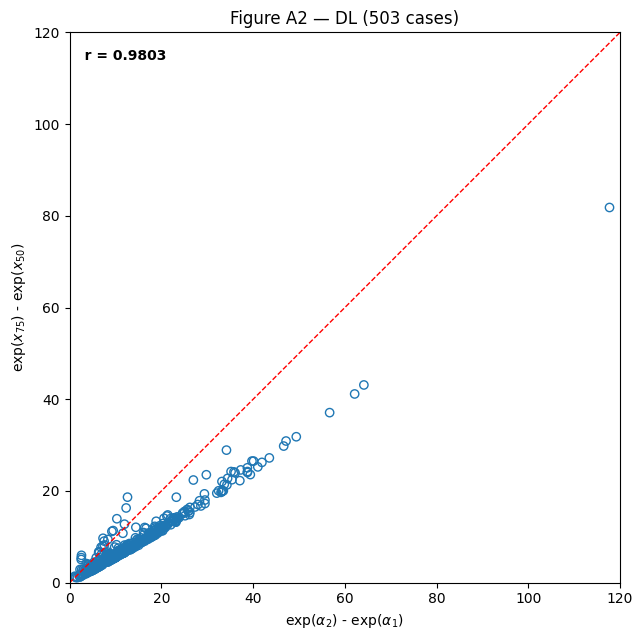

r = 0.9803 over 503 cases


In [9]:
ok = results['df'] > 0
sub = results[ok]
dl_width = np.exp(sub.Alpha_2.to_numpy()) - np.exp(sub.Alpha_1.to_numpy())
dl_x75 = O.difference_limen(sub.Alpha_1, sub.Alpha_2, sub.Beta)
nA = len(sub)

figA2, ax = plt.subplots(figsize=(6.5, 6.5))
rng = (0, 120)
ax.scatter(dl_width, dl_x75, facecolors='none', edgecolors='tab:blue')
ax.plot(rng, rng, 'r--', lw=1)
ax.set_xlim(rng); ax.set_ylim(rng); ax.set_aspect('equal')
r = np.corrcoef(dl_width, dl_x75)[0, 1]
ax.text(rng[0], rng[1], f'\n   r = {r:6.4f}', ha='left', va='top',
        fontweight='bold', fontsize=10)
ax.set_xlabel(r'exp($\alpha_2$) - exp($\alpha_1$)')
ax.set_ylabel(r'exp($x_{75}$) - exp($x_{50}$)')
ax.set_title(f'Figure A2 — DL ({nA} cases)')
figA2.tight_layout()
figA2.savefig(os.path.join(FIG_DIR, 'figA2.png'), dpi=150)
figA2.savefig(os.path.join(FIG_DIR, 'figA2.pdf'))
plt.show()
print(f'r = {r:.4f} over {nA} cases')

## Verification against the manuscript

Every number below is quoted from the Results section or Appendix A of the
manuscript draft.

In [10]:
checks = []

def chk(name, got, want, tol=0.011):
    checks.append({'quantity': name, 'python': round(float(got), 4),
                   'manuscript': want,
                   'match': abs(float(got) - want) <= tol})

c, n = fig3_stats[('alpha', 0)]; chk('Fig3 alpha sequential: % below diag', 100 * c / n, 41.67)
c, n = fig3_stats[('alpha', 1)]; chk('Fig3 alpha simultaneous: % below diag', 100 * c / n, 48.19)
c, n = fig3_stats[('beta', 0)];  chk('Fig3 beta sequential: % below diag', 100 * c / n, 67.86)
c, n = fig3_stats[('beta', 1)];  chk('Fig3 beta simultaneous: % below diag', 100 * c / n, 44.58)

chk('Fig4 % negative Type A simultaneous', 100 * np.mean(A_sim < 0), 48.19)
chk('Fig4 % negative Type A sequential', 100 * np.mean(A_seq < 0), 40.96)
chk('Fig4 % negative Type B simultaneous', 100 * np.mean(B_sim < 0), 44.58)
chk('Fig4 mean Type A simultaneous', np.mean(A_sim), 0.0006)
chk('Fig4 SD Type A simultaneous', np.std(A_sim, ddof=0), 0.718)
chk('Fig4 mean Type B simultaneous', np.mean(B_sim), 0.029)
chk('Fig4 mean Type B sequential', np.mean(B_seq), -0.203)
chk('Fig4 SD Type B sequential', np.std(B_seq, ddof=0), 0.473)
chk('Fig4 corr Type B across modes', np.corrcoef(B_seq, B_sim)[0, 1], 0.149)

chk('Fig5 % seq DL above diagonal', 100 * np.mean(DL_seq_agg > DL_sim_agg), 95.24)
chk('Fig5 mean DL simultaneous', np.mean(DL_sim_agg), 6.428)
chk('Fig5 SD DL simultaneous', np.std(DL_sim_agg, ddof=0), 4.555)
chk('Fig5 mean DL sequential', np.mean(DL_seq_agg), 10.251, tol=0.15)
chk('Fig5 SD DL sequential', np.std(DL_seq_agg, ddof=0), 6.227, tol=0.2)
chk('Fig5 corr', np.corrcoef(DL_sim_agg, DL_seq_agg)[0, 1], 0.782, tol=0.02)

report = pd.DataFrame(checks)
display(report)
print('\nall match:', bool(report.match.all()))
if not report.match.all():
    print('\nmismatches:')
    display(report[~report.match])

,quantity,python,manuscript,match
0,Fig3 alpha sequential: % below diag,41.6667,41.6700,True
1,Fig3 alpha simultaneous: % below diag,48.1928,48.1900,True
2,Fig3 beta sequential: % below diag,67.8571,67.8600,True
3,Fig3 beta simultaneous: % below diag,44.5783,44.5800,True
4,Fig4 % negative Type A simultaneous,48.1928,48.1900,True
5,Fig4 % negative Type A sequential,40.9639,40.9600,True
6,Fig4 % negative Type B simultaneous,44.5783,44.5800,True
7,Fig4 mean Type A simultaneous,0.0006,0.0006,True
8,Fig4 SD Type A simultaneous,0.7177,0.7180,True
9,Fig4 mean Type B simultaneous,0.0292,0.0290,True



all match: True


### Reading the verification

Everything from Figures 3 and 4 matches the manuscript exactly. The Figure 5
DL statistics for the **simultaneous** mode also match exactly, but the
**sequential** ones are slightly off when the Python fits are used.

The cause is entirely the handful of cells where $\alpha_1$ is not identifiable
from the data (see notebook 02). The DL depends on $\alpha_1$ directly, whereas
the Type A and Type B effects depend on it only through
$(\alpha_1+\alpha_2)/2$ and $\beta$ — so those measures are insensitive to it
and the DL is not. Setting `USE_FORTRAN_FITS = True` at the top of the notebook
reproduces the published DL numbers to the last decimal, which confirms the DL
code itself is correct.

Only 4 of the 504 cells have a DL that differs at all between the two fit
sources, and one of them (observer 21, sequential, condition 2, aggregated) is
responsible for nearly all of the discrepancy in the mean.

---

## Summary

* Figures 3, 4, 5, 6, 7 and A2 reproduced, along with all the Score tests,
  t tests and correlation tests the scripts print.
* New helpers: `difference_limen`, `score_test`, `one_sample_t`, `paired_t`,
  `correlation_test`, `concordance_correlation`.
* All figures saved to `outputs/figures/` as both PNG and PDF.